# Overview
In this notebook, we will build and train neural networks using [JAX](https://jax.readthedocs.io/). We will consider the following examples:

- MNIST dataset of handwritten digits
- Image reconstruction example

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax import random, grad
import optax
from keras.datasets import mnist
from PIL import Image
import matplotlib.pyplot as plt
from skimage import data

## MNIST example of handwritten digits
The MNIST dataset is a standard machine learning benchmark containing 70,000 grayscale 28x28 pixel images of handwritten digits from zero to nine. 
It can be loaded directly through most deep learning libraries like `keras.datasets` or downloaded manually from [Yann LeCun's official website](http://yann.lecun.com/).

- 60,000 for training
- 10,000 for testing

In [2]:
# Load MNIST data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(-1, 28*28) / 255.0
x_test  = x_test.reshape(-1, 28*28) / 255.0

y_train = jax.nn.one_hot(y_train, 10)
y_test  = jax.nn.one_hot(y_test, 10)

x_train = jnp.array(x_train)
y_train = jnp.array(y_train)
x_test  = jnp.array(x_test)
y_test  = jnp.array(y_test)

# Initialization 
def init_mnist_params(key):
    return {
        "W1": random.normal(key, (784, 128)) * 0.01,
        "b1": jnp.zeros(128),
        "W2": random.normal(key, (128, 10)) * 0.01,
        "b2": jnp.zeros(10),
    }

def mnist_forward(params, x):
    # can change activation function
    h = jax.nn.relu(x @ params["W1"] + params["b1"])
    return h @ params["W2"] + params["b2"]

def mnist_loss(params, x, y):
    logits = mnist_forward(params, x)
    return optax.softmax_cross_entropy(logits, y).mean()

# Accuracy method
def mnist_accuracy(params, x, y):
    logits = mnist_forward(params, x)
    preds = jnp.argmax(logits, axis=1)
    labels = jnp.argmax(y, axis=1)
    correct = jnp.sum(preds == labels)
    accuracy = correct / x.shape[0]
    return int(correct), float(accuracy)

In [3]:
# Batch GD
def train_minibatch(params, lr=0.01, steps=20000, batch_size=32):
    losses = []
    n_samples = x_train.shape[0]
    
    @jax.jit
    def update(p, x_b, y_b):
        g = grad(mnist_loss)(p, x_b, y_b)
        p = jax.tree_util.tree_map(lambda w, dw: w - lr * dw, p, g)
        return p, mnist_loss(p, x_b, y_b)

    # Generate all random indices at once for efficiency. 
    key = random.PRNGKey(37)
    indices = random.randint(key, shape=(steps, batch_size), minval=0, maxval=n_samples)

    for step in range(steps):
        # Get the batch indices for this specific step
        idx = indices[step]
        x_batch = x_train[idx]
        y_batch = y_train[idx]
        
        params, loss_val = update(params, x_batch, y_batch)
        losses.append(loss_val)

        if step % 2000 == 0:
            print(f"Iteration {step}, Loss: {loss_val:.4f}")
            
    return params, jnp.array(losses)


mnist_params = init_mnist_params(random.PRNGKey(1))

mbgd_params, mbgd_train_loss = train_minibatch(
    mnist_params, 
    lr=0.05,            
    steps=10000,        
    batch_size=128      
)

# Compute accuracy
mbgd_correct, mbgd_acc = mnist_accuracy(mbgd_params, x_test, y_test)

print(f"\nFinal Test Accuracy:   {mbgd_correct} / {len(x_test)}   ({mbgd_acc*100:.2f}%)")

Iteration 0, Loss: 2.3013
Iteration 2000, Loss: 0.2565
Iteration 4000, Loss: 0.1550
Iteration 6000, Loss: 0.0724
Iteration 8000, Loss: 0.1097

Final Test Accuracy:   9661 / 10000   (96.61%)


Alternatively, instead of testing the trained model on the prescribed testset, one could also just test their own handwritten digits.
The code below converts a handwritten digit picture from .jpg format into data that can be given to our trained NN.

[[ 1.3009223 -4.910263   4.687294   9.84269   -6.9265223  4.422522
  -6.1367936 -5.159851   8.09441   -5.3732743]]


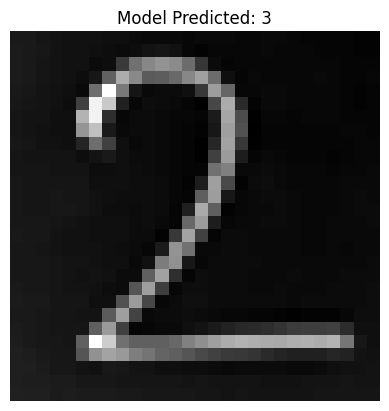

In [11]:
# Load the image and convert to grayscale ('L' mode)
image_path = "../2.jpg"  # Change this to your file's name
img = Image.open(image_path).convert('L')

# Resize to 28x28 pixels
img = img.resize((28, 28))

# Convert to a numpy array
img_array = np.array(img)

# INVERT COLORS 
img_array = 255 - img_array 
#img_array = np.where(img_array>130, 255, img_array)

# Normalize pixel values to [0, 1] just like our training data
img_array = img_array / 255.0

# Reshape to match the network's input shape: (1 sample, 784 pixels)
x_custom = img_array.reshape(1, 784)
x_custom = jnp.array(x_custom)

# Predict using your trained gradient descent parameters
logits = mnist_forward(mbgd_params, x_custom)
prediction = jnp.argmax(logits, axis=1)[0]
print(logits)

# Visualize 
plt.imshow(img_array, cmap='gray')
plt.title(f"Model Predicted: {prediction}")
plt.axis('off')
plt.show()

## Image Reconstruction: Memorizing with Neural Networks
In this example, we use the famous "Cameraman" dataset to demonstrate how neural networks can reconstruct visual data. Instead of feeding an image *through* the network, we train the network to *become* the image.

We treat the image as a physical coordinate grid. 
- **The Input:** We feed the network just two numbers: the (X, Y) space coordinates of a single pixel. 
- **The Output:** The network predicts the grayscale brightness for that exact location. 
- **The Reconstruction:** By guessing the brightness for every coordinate and correcting its mistakes via *optimization algorithms*, the original image is slowly memorized into the network's hidden layers. To reconstruct the final image, we simply ask the network to predict the color for every coordinate on a blank canvas.

Iteration 0, Loss: 0.0934
Iteration 500, Loss: 0.0288
Iteration 1000, Loss: 0.0274
Iteration 1500, Loss: 0.0265
Iteration 2000, Loss: 0.0278
Iteration 2500, Loss: 0.0255
Iteration 3000, Loss: 0.0219
Iteration 3500, Loss: 0.0242
Iteration 4000, Loss: 0.0188
Iteration 4500, Loss: 0.0131
Iteration 5000, Loss: 0.0238
Iteration 5500, Loss: 0.0116
Iteration 6000, Loss: 0.0127
Iteration 6500, Loss: 0.0174
Iteration 7000, Loss: 0.0176
Iteration 7500, Loss: 0.0288
Iteration 8000, Loss: 0.0093
Iteration 8500, Loss: 0.0162
Iteration 9000, Loss: 0.0102
Iteration 9500, Loss: 0.0101
Iteration 10000, Loss: 0.0188
Iteration 10500, Loss: 0.0083
Iteration 11000, Loss: 0.0269
Iteration 11500, Loss: 0.0139
Iteration 12000, Loss: 0.0166
Iteration 12500, Loss: 0.0114
Iteration 13000, Loss: 0.0176
Iteration 13500, Loss: 0.0081
Iteration 14000, Loss: 0.0075
Iteration 14500, Loss: 0.0154
Iteration 15000, Loss: 0.0143
Iteration 15500, Loss: 0.0171
Iteration 16000, Loss: 0.0091
Iteration 16500, Loss: 0.0182
Iter

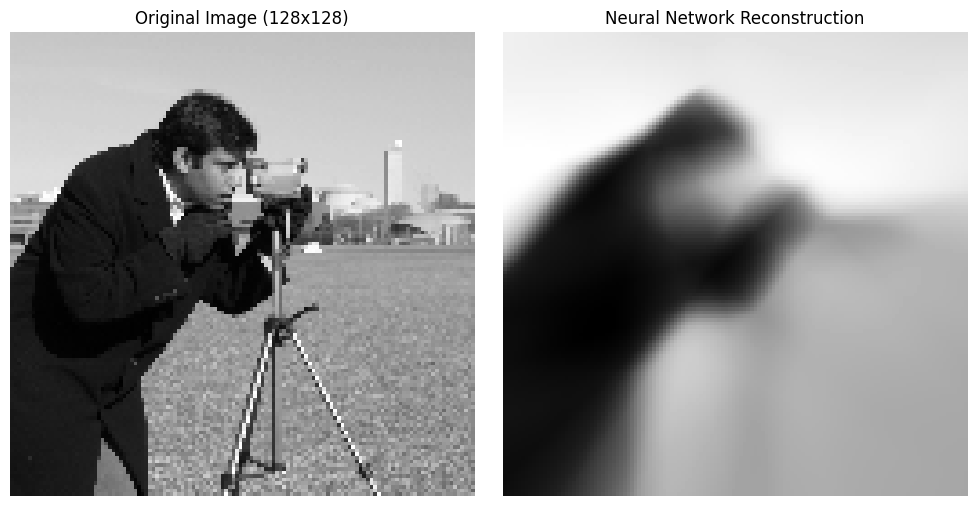

In [15]:
# Load the Cameraman
original_img = data.camera()

# Downsample it to 128x128 so it trains instantly
img = original_img[::4, ::4] / 255.0
H, W = img.shape

# Create the dataset: (X, Y) inputs -> Pixel brightness output
x_coords = np.linspace(-1, 1, W)
y_coords = np.linspace(-1, 1, H)
xx, yy = np.meshgrid(x_coords, y_coords)

# Flatten into lists of inputs (coordinates) and outputs (pixels)
X_data = jnp.array(np.c_[xx.ravel(), yy.ravel()], dtype=jnp.float32)
Y_data = jnp.array(img.ravel().reshape(-1, 1), dtype=jnp.float32)


# Initialization and model
def init_camera_params(key):
    # 4 hidden layers of 128 neurons
    keys = random.split(key, 5)
    return {
        "W1": random.normal(keys[0], (2, 128)) * 0.1,  "b1": jnp.zeros(128),
        "W2": random.normal(keys[1], (128, 128)) * 0.1, "b2": jnp.zeros(128),
        "W3": random.normal(keys[2], (128, 128)) * 0.1, "b3": jnp.zeros(128),
        "W4": random.normal(keys[3], (128, 128)) * 0.1, "b4": jnp.zeros(128),
        "W5": random.normal(keys[4], (128, 1)) * 0.1,   "b5": jnp.zeros(1),
    }

def camera_forward(params, x):
    h = jax.nn.relu(x @ params["W1"] + params["b1"])
    h = jax.nn.relu(h @ params["W2"] + params["b2"])
    h = jax.nn.relu(h @ params["W3"] + params["b3"])
    h = jax.nn.relu(h @ params["W4"] + params["b4"])
    # Use sigmoid at the end to ensure the output brightness is strictly between 0 and 1
    return jax.nn.sigmoid(h @ params["W5"] + params["b5"])

# Mean Squared Error for regression
def mse_loss(params, x, y):
    preds = camera_forward(params, x)
    return jnp.mean((preds - y) ** 2)


def train_camera_minibatch(params, lr=0.5, steps=2000, batch_size=32):
    n_samples = X_data.shape[0]
    
    @jax.jit
    def update(p, x_b, y_b):
        # Calculate loss and gradients on the mini-batch
        loss_val, g = jax.value_and_grad(mse_loss)(p, x_b, y_b)

        p = jax.tree_util.tree_map(lambda pw, gw: pw - lr * gw, p, g)
        
        return p, loss_val

    key = random.PRNGKey(52)
    indices = random.randint(key, shape=(steps, batch_size), minval=0, maxval=n_samples)

    losses = []
    for step in range(steps):
        # Get the batch indices for this step
        idx = indices[step]
        
        x_batch = X_data[idx]
        y_batch = Y_data[idx]
        
        params, loss_val = update(params, x_batch, y_batch)
        losses.append(loss_val)
        
        if step % 500 == 0:
            print(f"Iteration {step}, Loss: {loss_val:.4f}")
            
    return params, jnp.array(losses)

# Run it
params = init_camera_params(random.PRNGKey(7))

trained_cam_params, cam_losses = train_camera_minibatch(params, lr=0.1,  steps=20000, batch_size=64)

# Visualize the Reconstruction
predicted_pixels = camera_forward(trained_cam_params, X_data)
reconstructed_img = predicted_pixels.reshape(H, W)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title("Original Image (128x128)")
axes[0].axis('off')

axes[1].imshow(reconstructed_img, cmap='gray')
axes[1].set_title("Neural Network Reconstruction")
axes[1].axis('off')

plt.tight_layout()
plt.show()